In [1]:
import torch

flushing = torch.set_flush_denormal(True)
print(f"Floating point flushing is set to {flushing}")

torch.manual_seed(0)
torch.set_num_threads(1)

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")
print(f"Using device: {device}")

Floating point flushing is set to True
Using device: cpu


In [247]:
import torch
import torch.nn as nn
from typing import Any

from thesis_code.network_components.neurons import MaskedRLeaky, MaskedRSynaptic
from thesis_code.network_components.linears import DaleslawLinear, MaskedKaimingLinear

class RecurrentLayer(nn.Module):
    def __init__(self,
        forward_matrix: torch.Tensor,
        recurrent_matrix: torch.Tensor,
        refractory_period: int = 0,
    ) -> None:
        super().__init__()
        self.n_neurons = recurrent_matrix.shape[0]

        assert forward_matrix.shape[1] == self.n_neurons, \
            f"forward_matrix outputs {forward_matrix.shape[1]} neurons, recurrent_matrix has {self.n_neurons}"

        self.weights = DaleslawLinear(forward_matrix)
        print(self.weights.get_weights())
        print("Input weights are all positive")

        assert isinstance(refractory_period, int) and refractory_period >= 0, \
            "refractory_period is set incorrectly"

        self.refractory_period = refractory_period
        self.refractory_buffer: torch.Tensor | None = None

    def reset(self) -> None:
        self._reset_neuron_state()
        self.weights.reset()
        self.refractory_buffer = None

    def _reset_neuron_state(self) -> None:
        raise NotImplementedError

    def get_weights(self) -> tuple[torch.Tensor, torch.Tensor]:
        return self.weights.get_weights(), self.neurons.get_recurrent_weights()

    def _compute_refractory_period(self, spk: torch.Tensor, mem: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        """
        Sets a mask to mute all spiking activity for a neuron activity for n timesteps after this neuron has spiked has occurred.
        Also keeps membrane potential at 0 (in snntorch language. This corresponds with -70mV in real-life).
        It leaves the synapses of SynapticRecurrentLayer alone.

        Inspired by:
        Li, Yang, Xinyi Zeng, Zhe Xue, Pinxian Zeng, Zikai Zhang, and Yan Wang. 2025. 
        “Incorporating the Refractory Period into Spiking Neural Networks through Spike-Triggered Threshold Dynamics.” 
        In arXiv [Cs.CV]. September 22. arXiv. https://doi.org/10.48550/arXiv.2509.17769.
        """
        if self.refractory_period <= 0:
            return spk, mem

        if self.refractory_buffer is None or self.refractory_buffer.shape != spk.shape:
            self.refractory_buffer = torch.zeros_like(spk, dtype=torch.int16)

        # print(f"Refractory buffer is: {self.refractory_buffer}")

        refractory = self.refractory_buffer > 0
        # print(f"Refractory is: {refractory}")

        # print(f"Spikes before mask: {spk}")
        spk = spk.masked_fill(refractory, 0.0)                      # disable spiking for neurons in refractory periods
        # print(f"Spikes after mask: {spk}")

        # print(f"Mems before clamp: {mem}")
        # mem = torch.where(refractory, torch.zeros_like(mem), mem)   # clamp mems to 0 for neurons in refractory periods
        # print(f"Mems after clamp: {mem}")

        self.refractory_buffer = torch.where(
            spk > 0,
            torch.full_like(self.refractory_buffer, self.refractory_period),    # set the buffer to the integer number of timesteps the buffer should apply if spiking
            (self.refractory_buffer - 1).clamp_min(0),                          # decrease the buffer by 1 for each timestep and clamp to 0
        )
        return spk, mem

    def _step(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        raise NotImplementedError

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        return self._step(self.weights(x))

    def forward_sequence(self, x_seq: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        x_seq = self.weights(x_seq)
        spks, mems = zip(*[self._step(x) for x in x_seq.unbind(0)])
        return torch.stack(spks, dim=0), torch.stack(mems, dim=0)

class StandardRecurrentLayer(RecurrentLayer):
    def __init__(self,
        forward_matrix: torch.Tensor,
        recurrent_matrix: torch.Tensor,
        beta: torch.Tensor | float,
        spike_grad: Any,
        fully_learnable: bool = True,
        refractory_period: int = 0,
    ) -> None:
        super().__init__(forward_matrix, recurrent_matrix, refractory_period)
        self.neurons = MaskedRLeaky(
            beta=beta,
            linear_features=self.n_neurons,
            init_hidden=False,
            spike_grad=spike_grad,
            learn_beta=fully_learnable,
            rec_matrix=recurrent_matrix,
            threshold=torch.ones(self.n_neurons),
            reset_delay=False,
            reset_mechanism="zero",
        )
        self.spk, self.mem = self.neurons.init_rleaky()

    def _reset_neuron_state(self) -> None:
        self.spk, self.mem = self.neurons.init_rleaky()
        self.neurons.reset_recurrent_weights()

    def _step(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        # self.spk, self.mem = self.neurons(x, self.spk, self.mem)
        spk, mem = self.neurons(x, self.spk, self.mem)
        self.spk, self.mem = self._compute_refractory_period(spk, mem)
        return self.spk, self.mem

In [248]:
import torch
import torch.nn as nn

from thesis_code.network_components.linears import DaleslawLinear
from thesis_code.network_components.layers import OutputLayer

class SRNN(nn.Module):
    def __init__(self,
            rec_layers: list = [],
            out_layer: OutputLayer | None = None,
        ) -> None:
        super().__init__()

        self.rec_layers = nn.ModuleList(rec_layers)
        self.out_layer = out_layer

    def reset(self) -> None:
        for layer in self.rec_layers:
            layer.reset()
        self.out_layer.reset()

    def get_weights(self) -> list[tuple[torch.Tensor, torch.Tensor | None]]:
        w_rec = [layer.get_weights() for layer in self.rec_layers]
        w_rec.append((self.out_layer.get_weights(), None))
        return w_rec

    def forward(self, data: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor, list[torch.Tensor]]:
        self.reset()

        spk_outs, mem_outs = [], []
        hidden_spks = [[] for _ in range(len(self.rec_layers))]
        hidden_mems = [[] for _ in range(len(self.rec_layers))]

        for step in range(data.size(0)):
            x = data[step]
            for i, layer in enumerate(self.rec_layers):
                x, m = layer(x)
                hidden_spks[i].append(x)
                hidden_mems[i].append(m)

            spk_out, mem_out = self.out_layer(x)
            spk_outs.append(spk_out)
            mem_outs.append(mem_out)

        return torch.stack(spk_outs, dim=0), torch.stack(mem_outs, dim=0), [torch.stack(spks_h, dim=0) for spks_h in hidden_spks], [torch.stack(mem_h, dim=0) for mem_h in hidden_mems]

    def forward_sequence(self, data: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor, list[torch.Tensor], list[torch.Tensor]]:
        self.reset()
        
        hidden_spks = []
        hidden_mems = []

        x_seq = data
        for layer in self.rec_layers:
            x_seq, m_seq = layer.forward_sequence(x_seq)
            hidden_spks.append(x_seq)
            hidden_mems.append(m_seq)
        spk_outs, mem_outs = self.out_layer.forward_sequence(x_seq)

        return spk_outs, mem_outs, hidden_spks, hidden_mems

    def apply_daleslaw(self) -> None:
        for m in self.modules():
            if isinstance(m, DaleslawLinear):
                m.apply_daleslaw()

In [ ]:
import snntorch.spikeplot as splt
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
from matplotlib.animation import ArtistAnimation
from IPython.display import HTML
import numpy as np

def plot_spikes(spike_matrix: np.ndarray, title: str) -> None:
    fig = plt.figure(facecolor="w", figsize=(25, 5))
    ax = fig.add_subplot(111)
    splt.raster(spike_matrix, ax, c="black")
    ax.set_xticks(np.arange(int(0), int(spike_matrix.shape[0]) + 1))
    ax.tick_params(axis="x", labelsize=8)

    plt.title(title)
    plt.xlabel("Time Steps")
    plt.ylabel("Neuron Number")

def plot_membrane_potentials(mem_data: np.ndarray, spike_matrix: np.ndarray, spike_threshold: float, title: str) -> None:
    n_steps, n_neurons = mem_data.shape
    fig, axes = plt.subplots(3 * n_neurons, 1, sharex=True, figsize=(25, 4 * n_neurons), squeeze=False, gridspec_kw={"height_ratios": [1, 3, 1] * n_neurons})
    for i in range(n_neurons):
        hide_ax = axes[3 * i, 0]
        hide_ax.axis("off")

        mem_ax = axes[3 * i + 1, 0]
        mem_ax.plot(mem_data[:, i], lw=1, label=f"Membrane traces")
        mem_ax.axhline(spike_threshold, c="red", ls="--", label=f"Spiking threshold = {spike_threshold}")
        mem_ax.set_ylabel("Membrane potential (V)")
        mem_ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
        mem_ax.legend(loc="upper right")
        mem_ax.set_title(f"Neuron {i + 1}")

        spk_ax = axes[3 * i + 2, 0]
        spike_times = np.nonzero(spike_matrix[:, i])[0]
        spk_ax.eventplot(spike_times, lineoffsets=0.5, linelengths=0.3, colors="black")
        spk_ax.set_ylim(0, 1)
        spk_ax.set_yticks([])
        spk_ax.set_ylabel("Spikes", rotation=0, labelpad=25)
        spk_ax.tick_params(labelbottom=True)

    bottom = axes[-1, 0]
    bottom.set_xlim(-0.5, n_steps - 0.5)
    bottom.set_xticks(np.arange(int(0), int(n_steps) + 1))
    bottom.tick_params(axis="x", labelsize=8)
        
    fig.suptitle(title)
    fig.supxlabel("Time Steps")
    fig.tight_layout()

def animate_spike_counts(spike_matrix: np.ndarray, title: str) -> ArtistAnimation:
    n_steps, n_neurons = spike_matrix.shape
    labels = [f"Neuron {i}" for i in range(1, n_neurons + 1)]

    fig, ax = plt.subplots(facecolor='w', figsize=(12, 7))
    fig.suptitle(title)
    anim = splt.spike_count(torch.from_numpy(spike_matrix), fig, ax, labels, interpolate=5, num_steps=n_steps, time_step=1e-3, animate=True)
    HTML(anim.to_html5_video())
    # anim.save(f"{title}.gif")

In [224]:
def isi_per_neuron(spikes, time_axis=0):
    s = spikes != 0
    s = np.moveaxis(s, time_axis, -1)          # (..., T)
    s = s.reshape(-1, s.shape[-1])             # (n_neurons, T)

    mins = np.full(s.shape[0], np.nan)
    for i, row in enumerate(s):
        t = np.flatnonzero(row)                # spike times of neuron i
        if t.size > 1:
            mins[i] = np.diff(t).min()
    return mins

tensor([[0.1671],
        [0.0133],
        [0.5954],
        [0.7687]])
Input weights are all positive
The minimum distance between any two spikes = [nan  3.  2.  2.], which should be higher than the set refractory period of 0


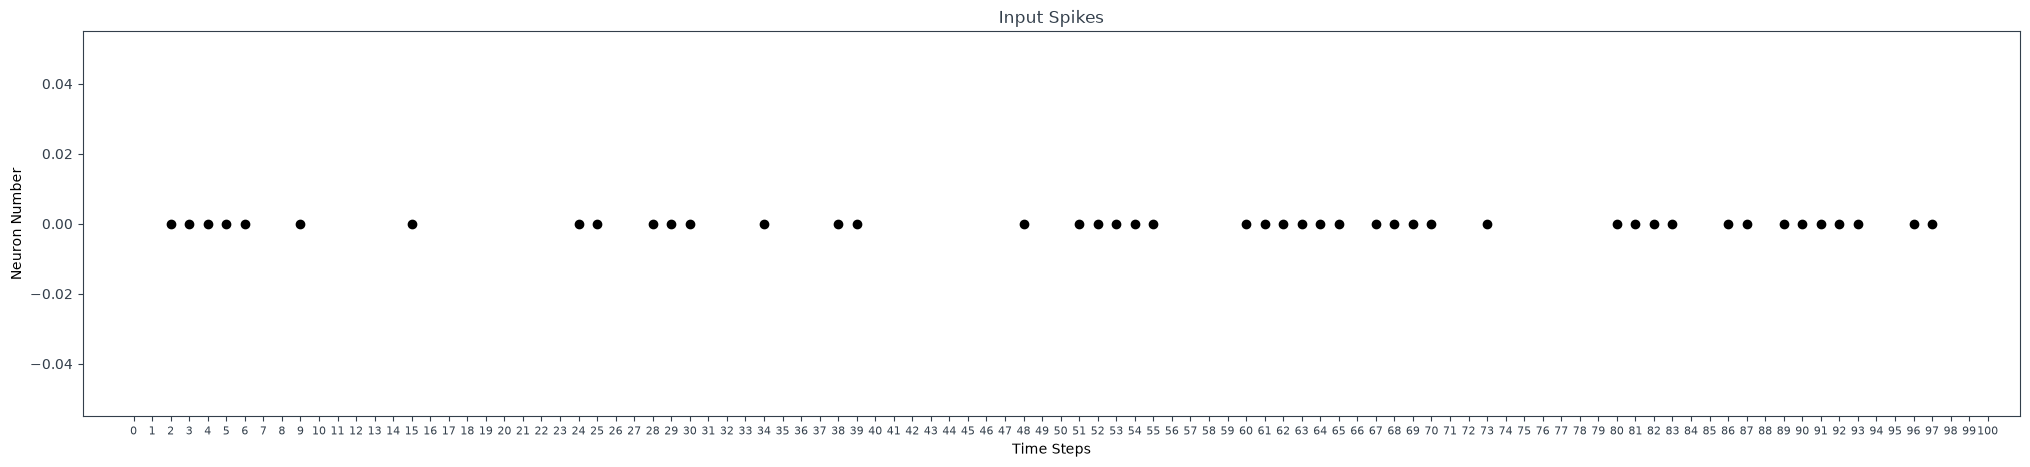

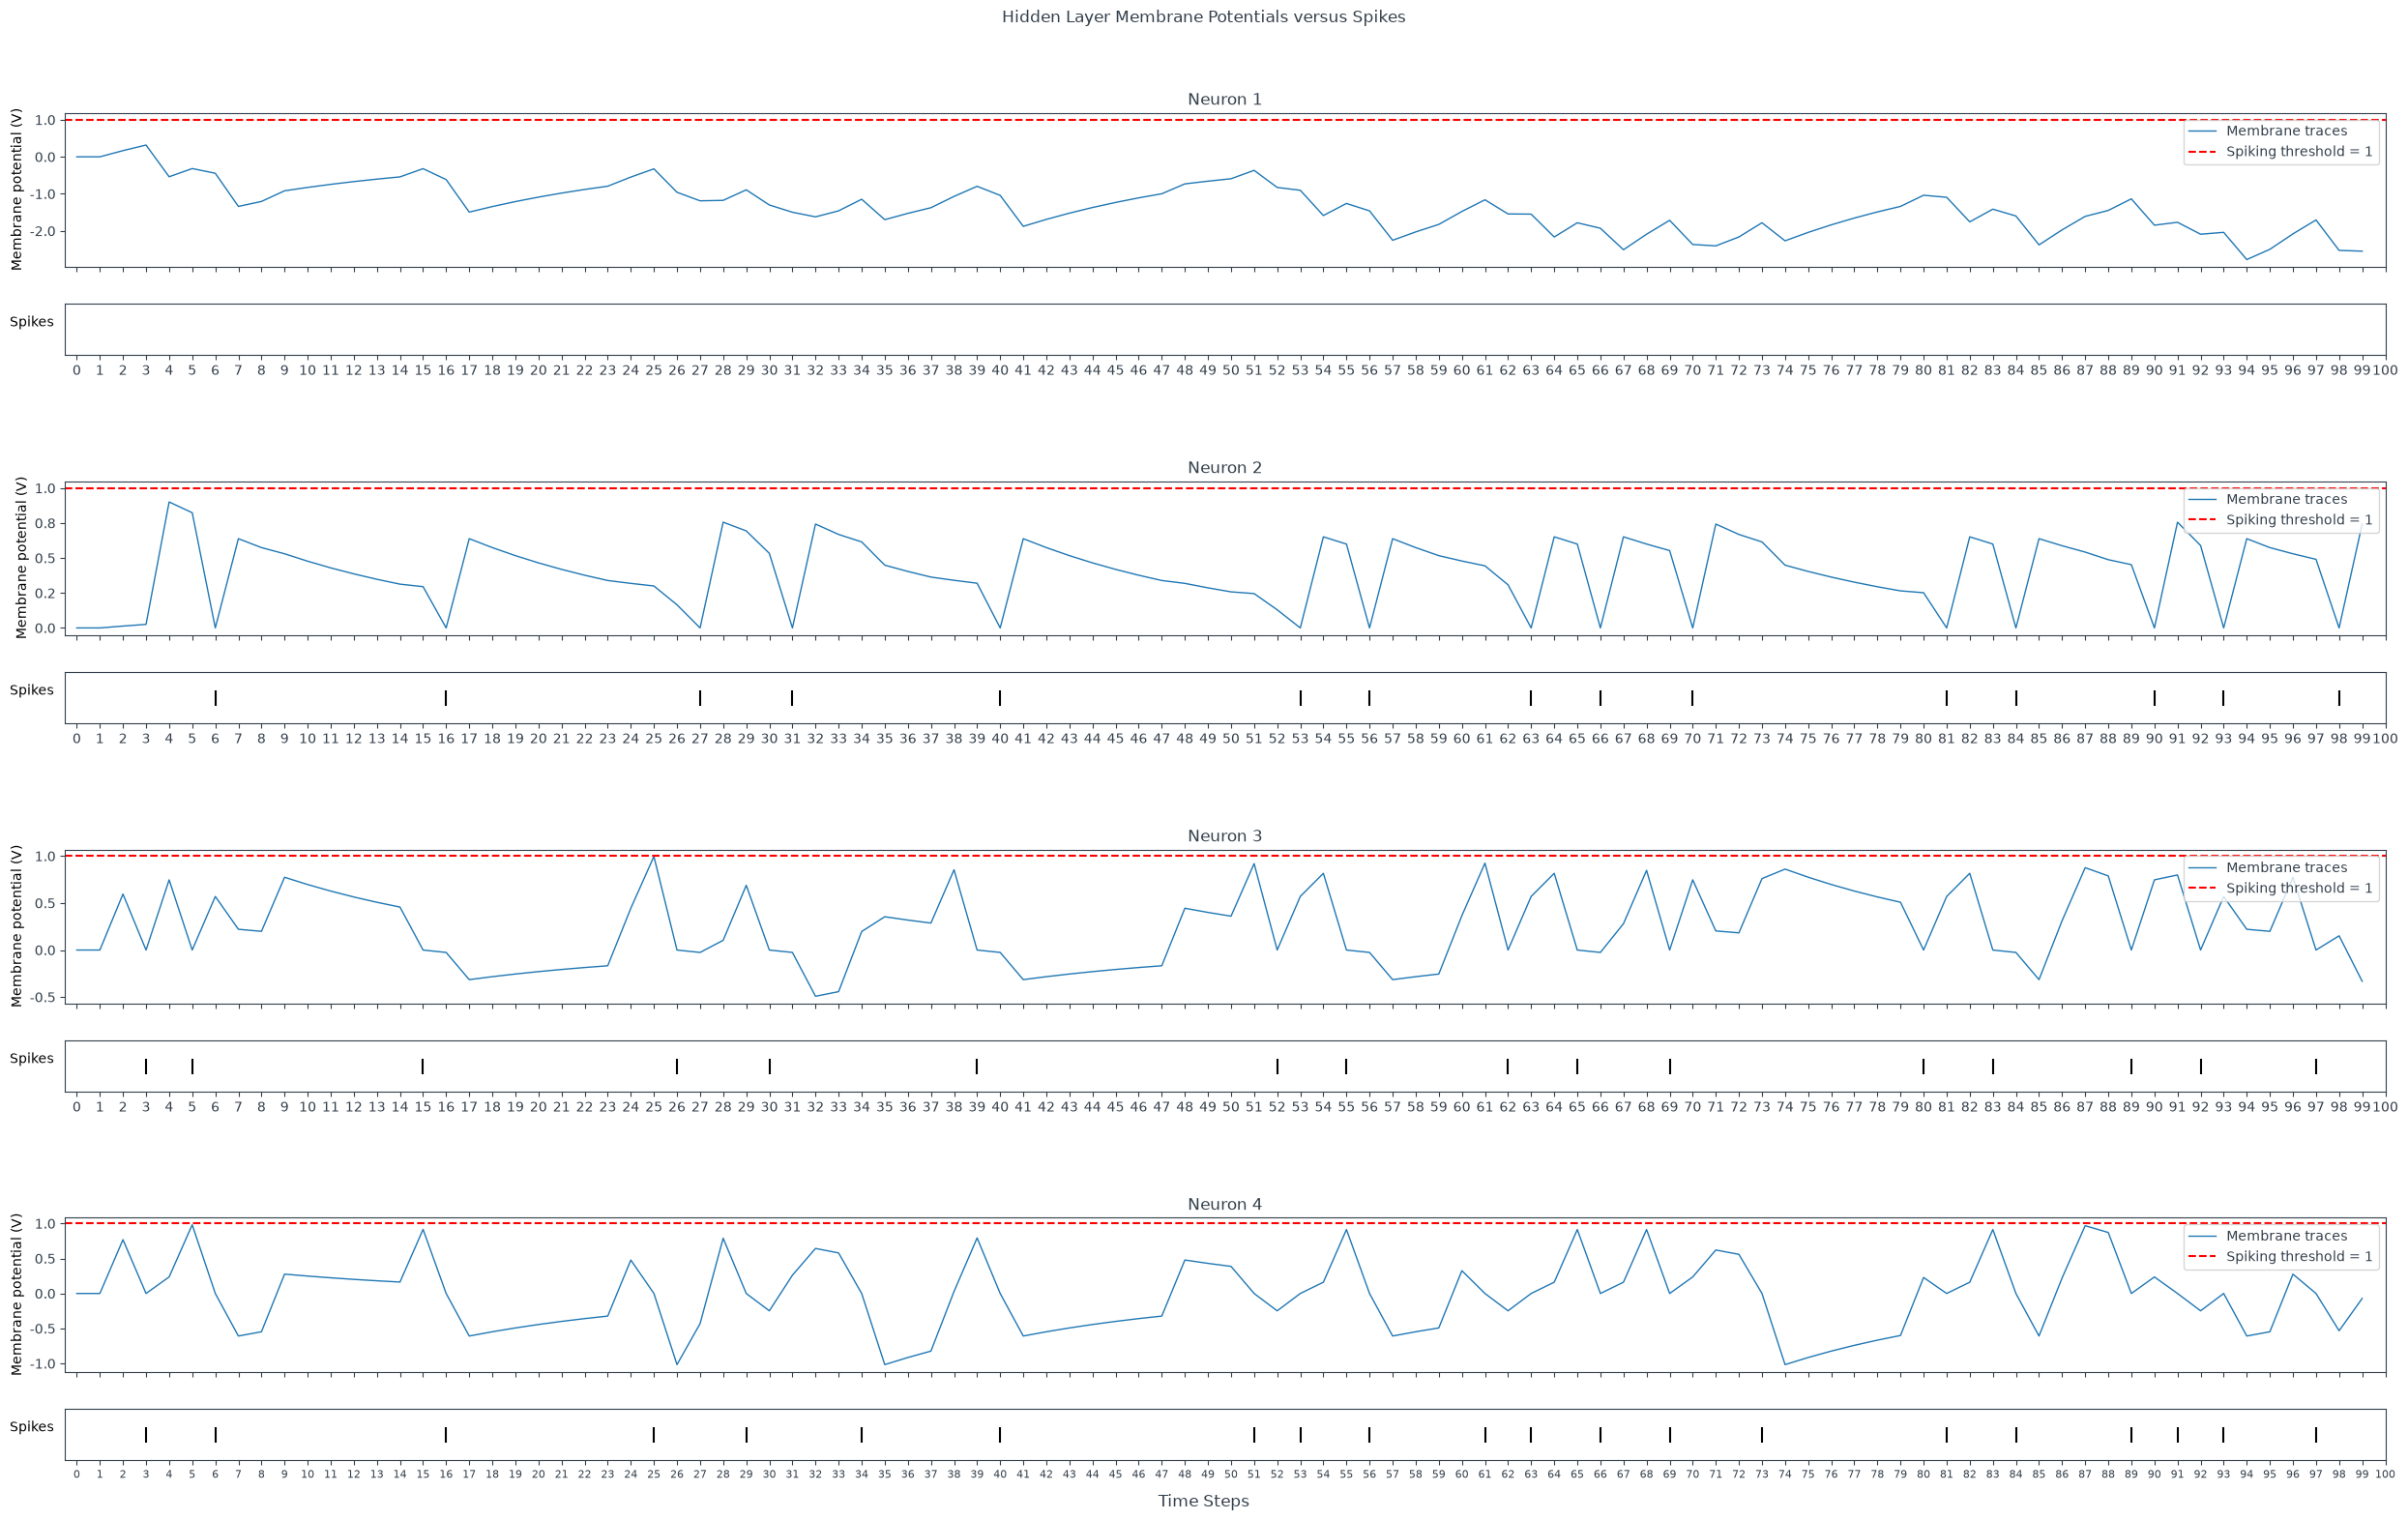

tensor([[0.2675],
        [0.1178],
        [0.9302],
        [1.3861]])
Input weights are all positive
The minimum distance between any two spikes = [ 3. nan  3.  2.], which should be higher than the set refractory period of 1


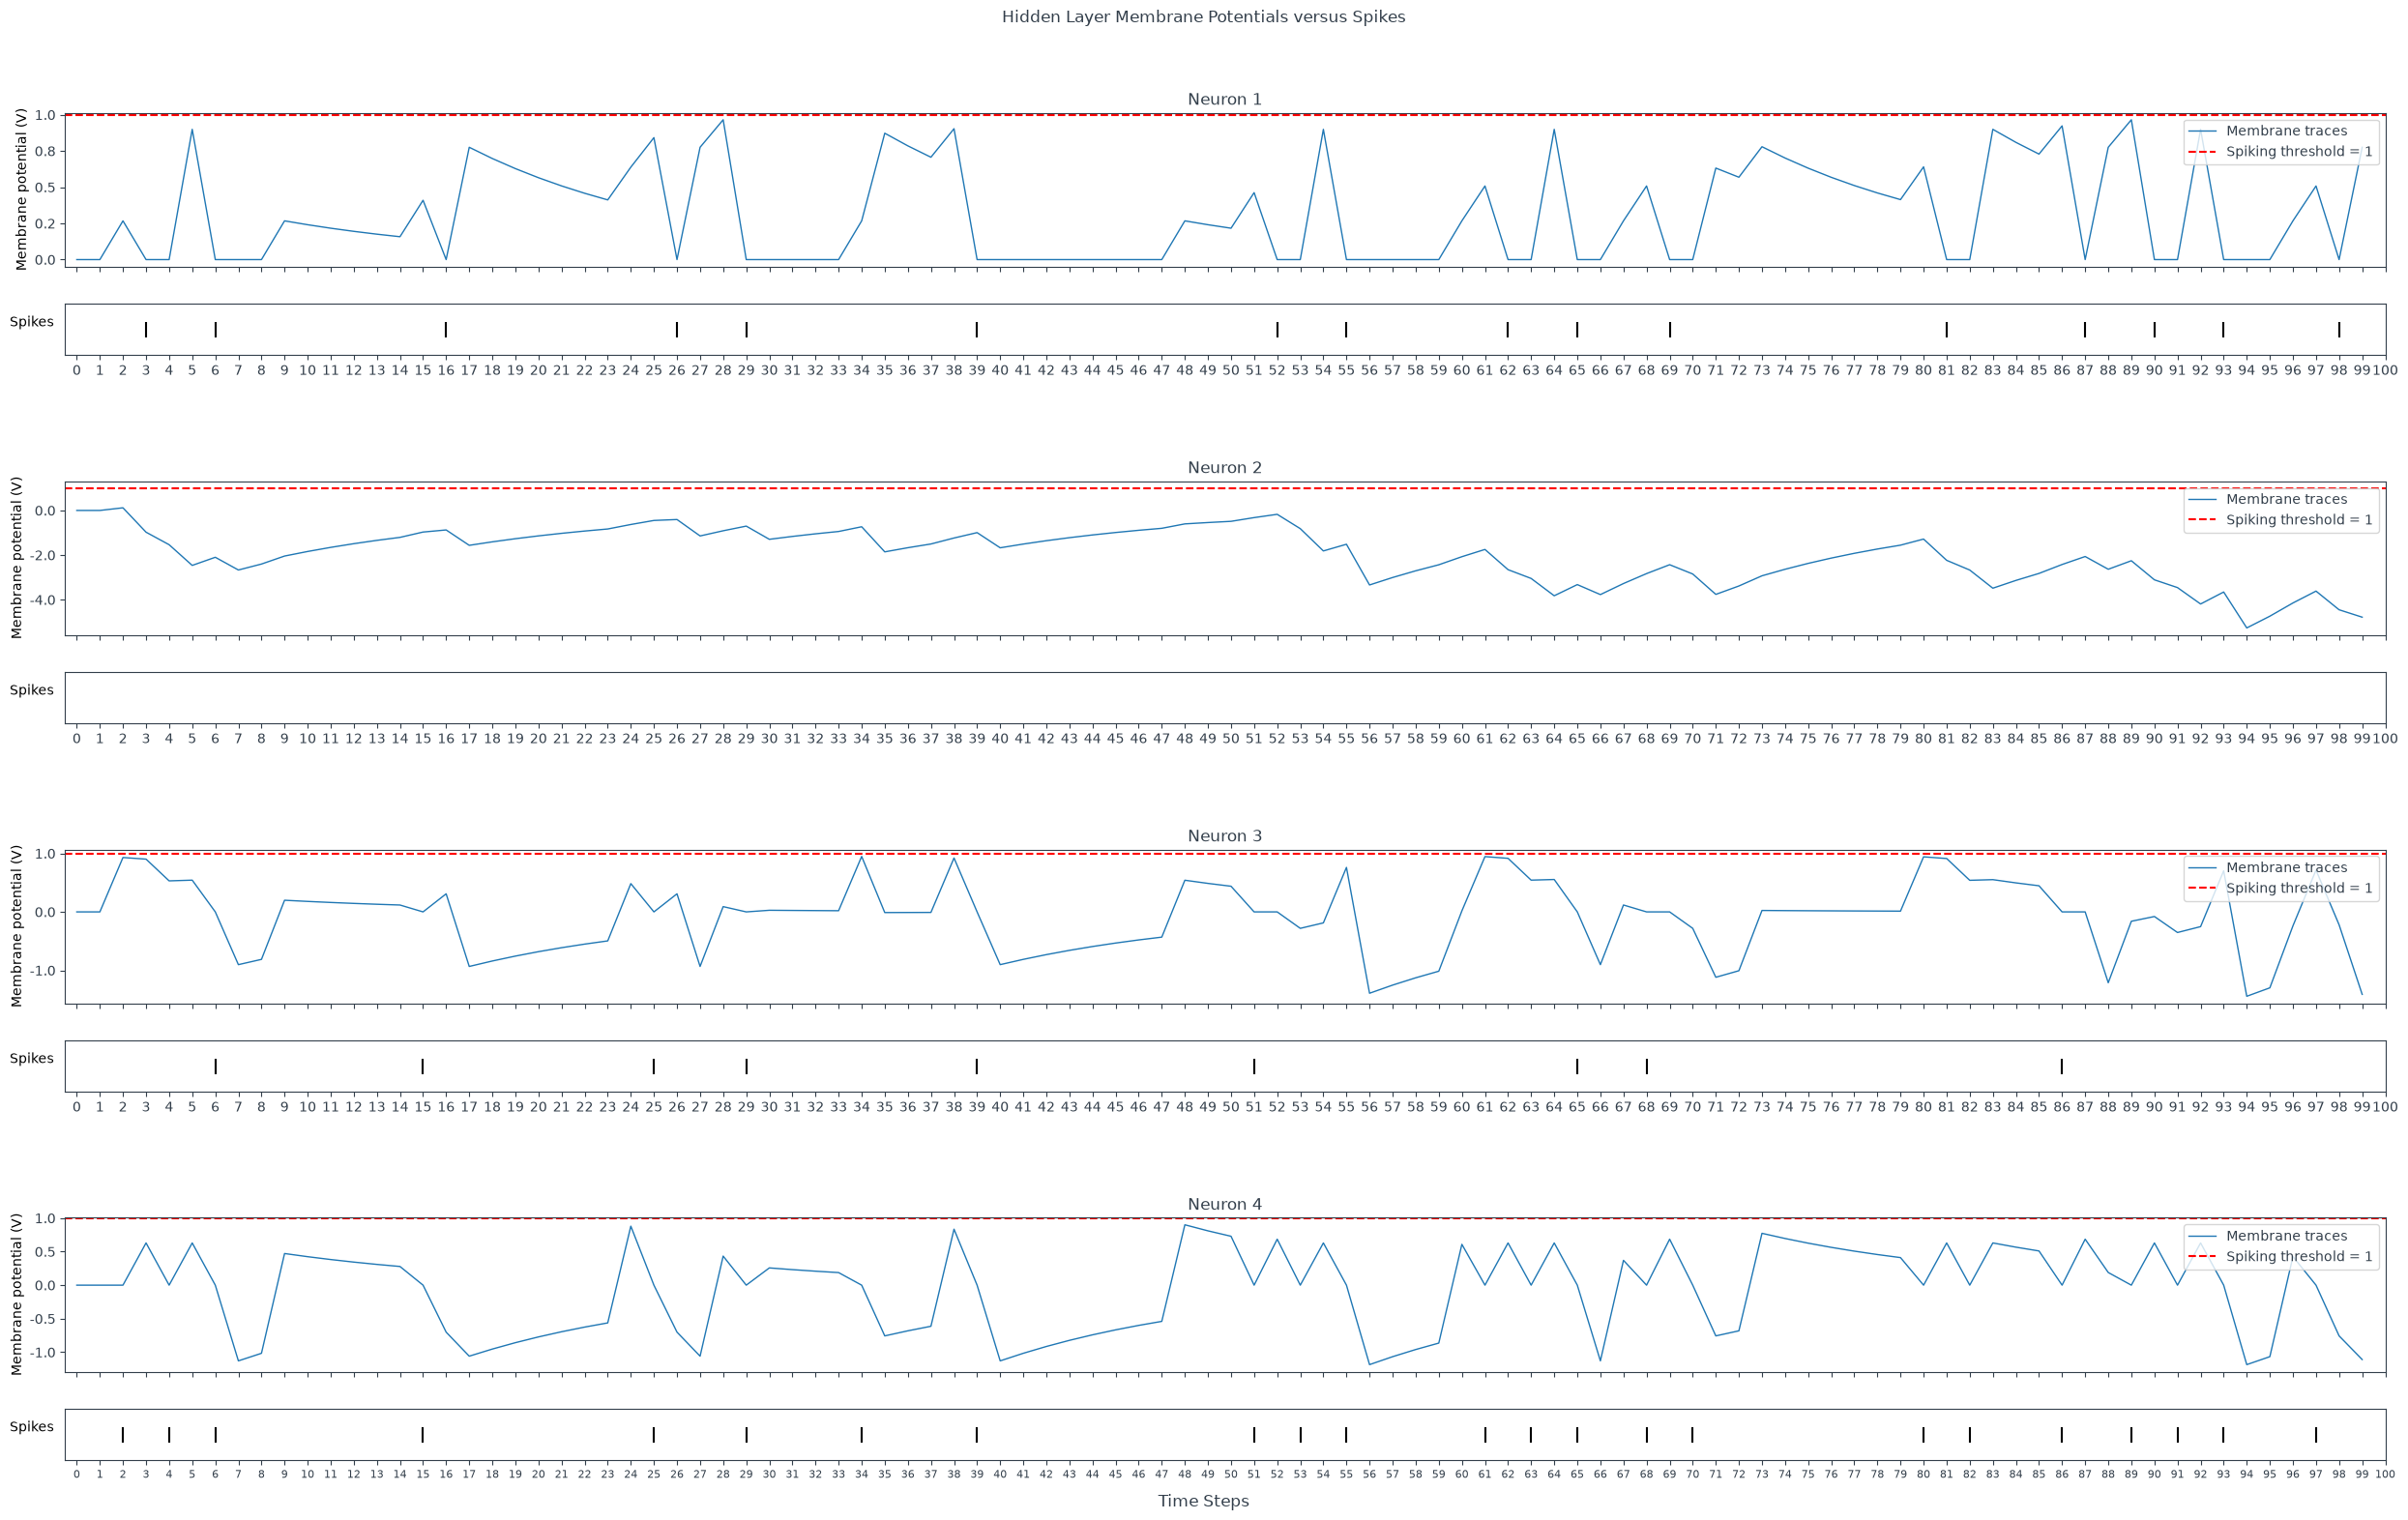

tensor([[0.1920],
        [0.2575],
        [1.8130],
        [0.6774]])
Input weights are all positive
The minimum distance between any two spikes = [nan nan  3.  3.], which should be higher than the set refractory period of 2


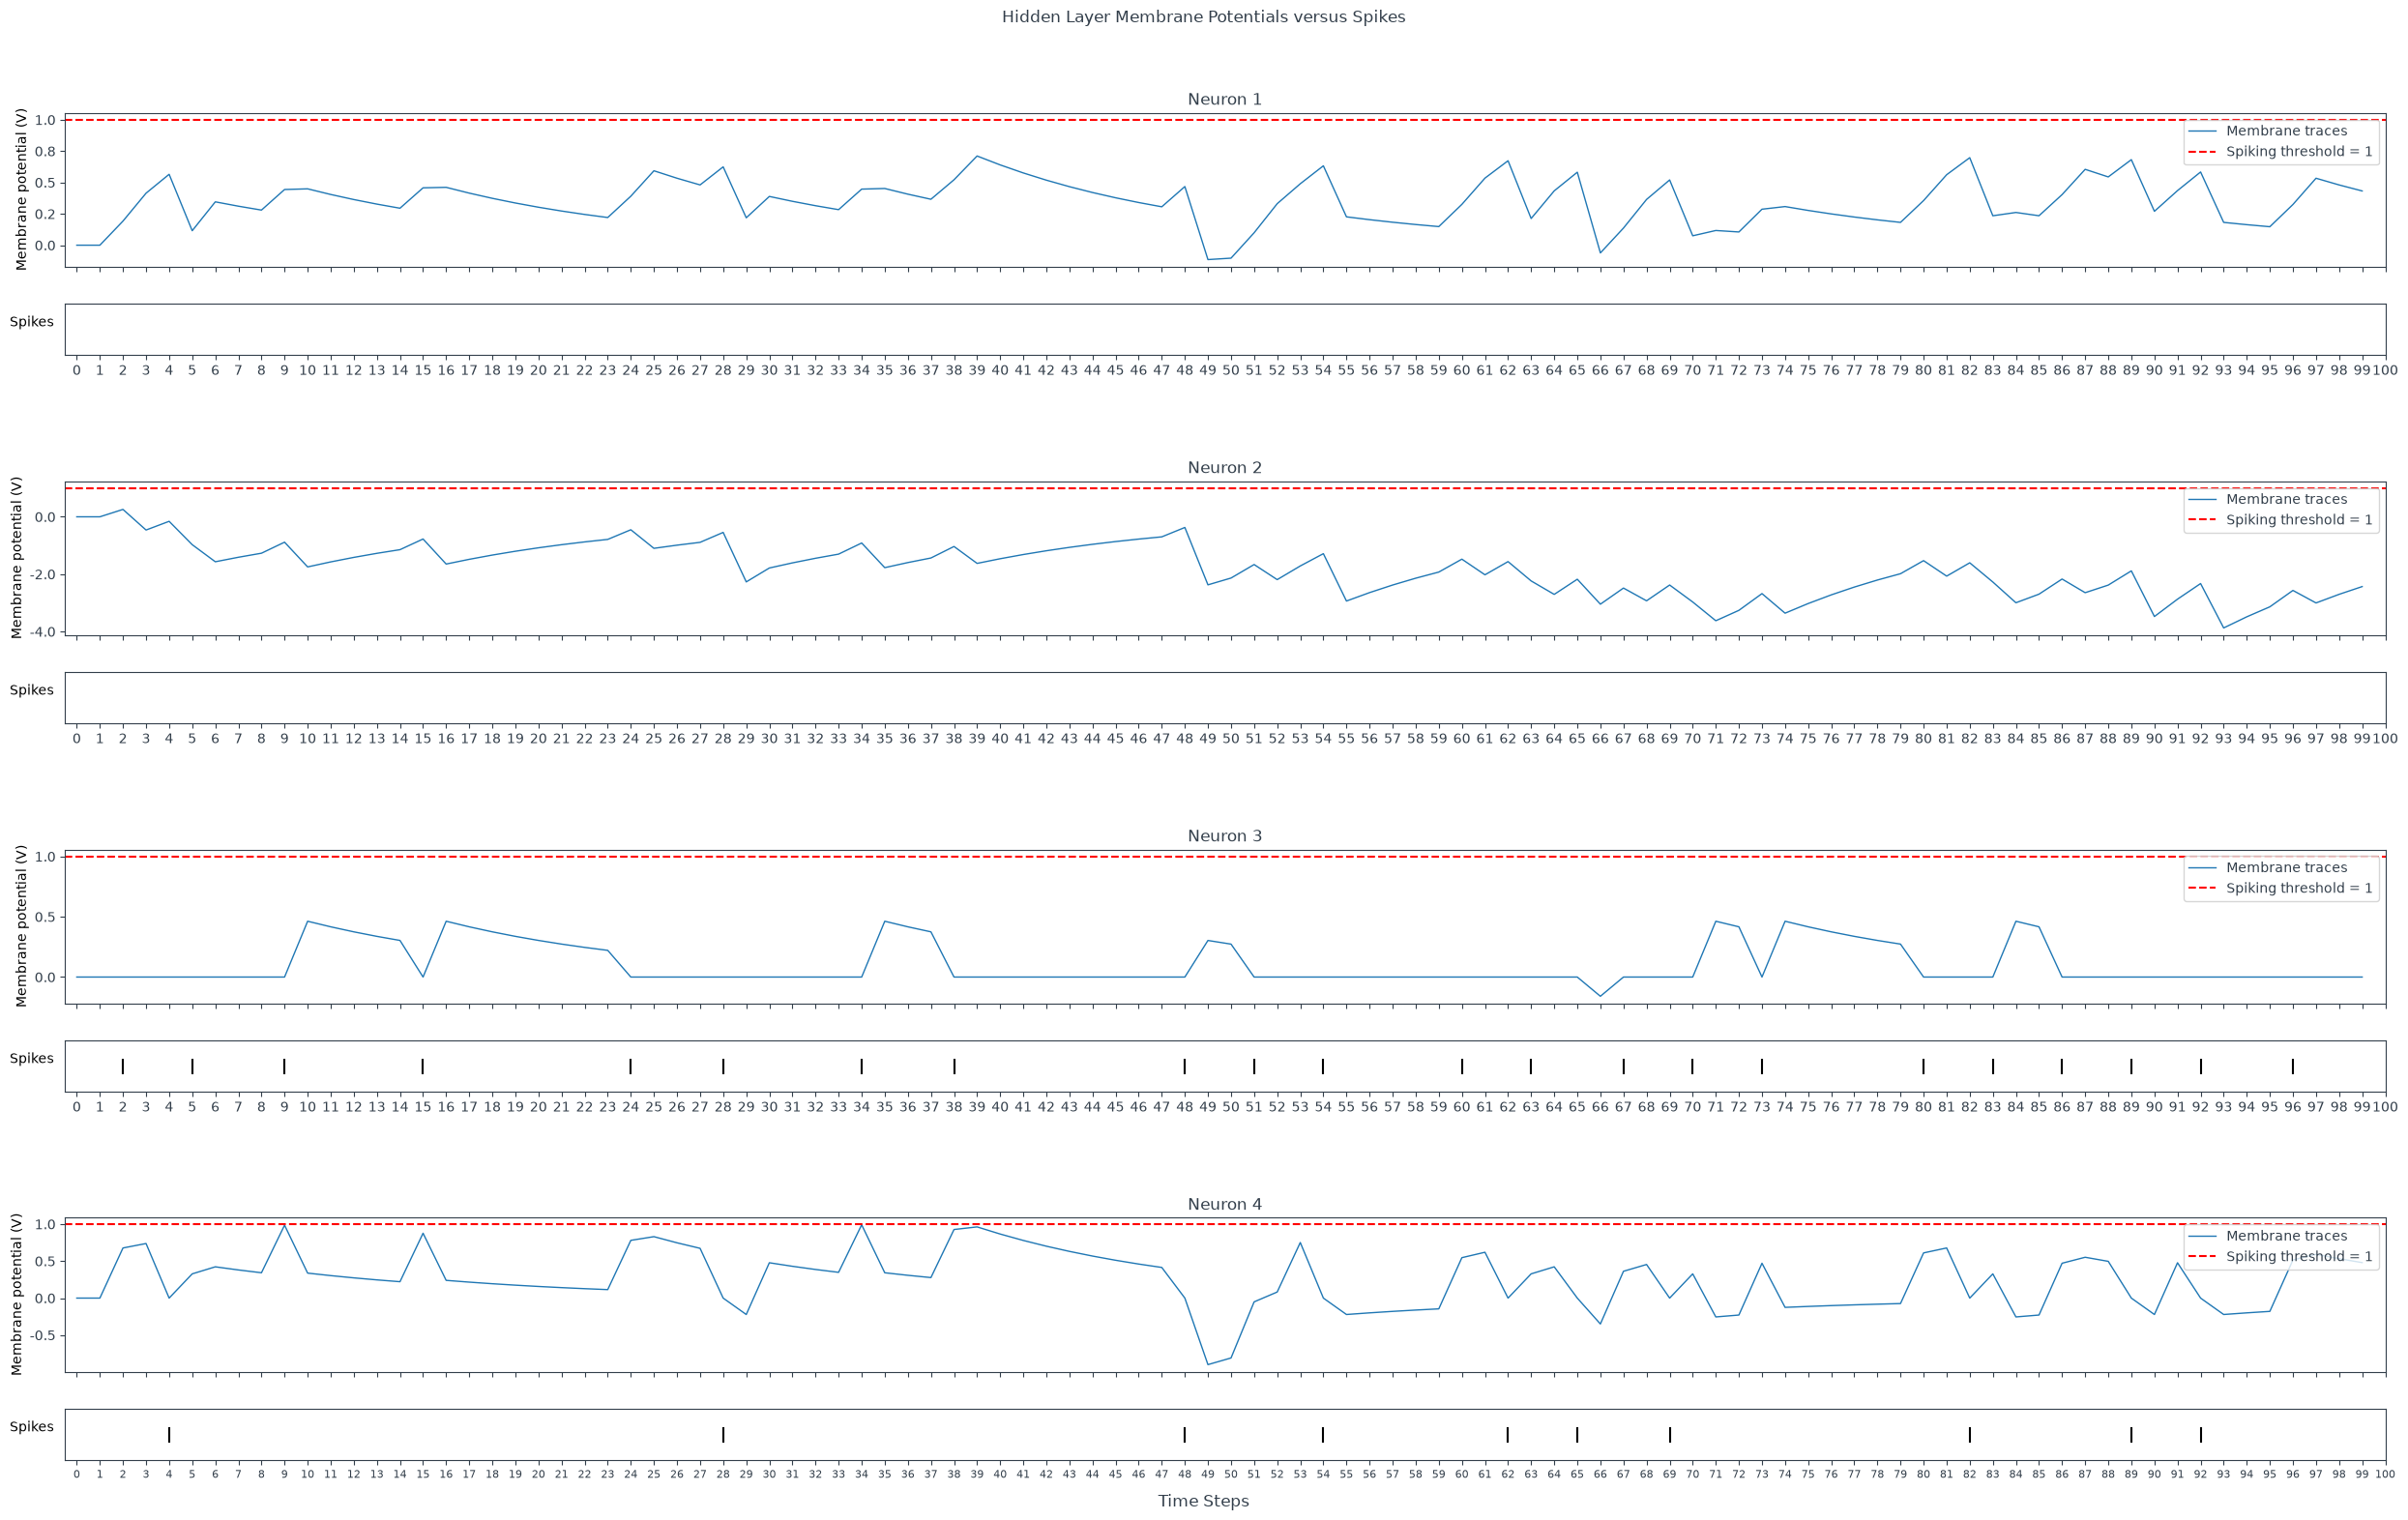

tensor([[0.4546],
        [0.7849],
        [0.3982],
        [0.2947]])
Input weights are all positive
The minimum distance between any two spikes = [ 6.  4. 17.  4.], which should be higher than the set refractory period of 3


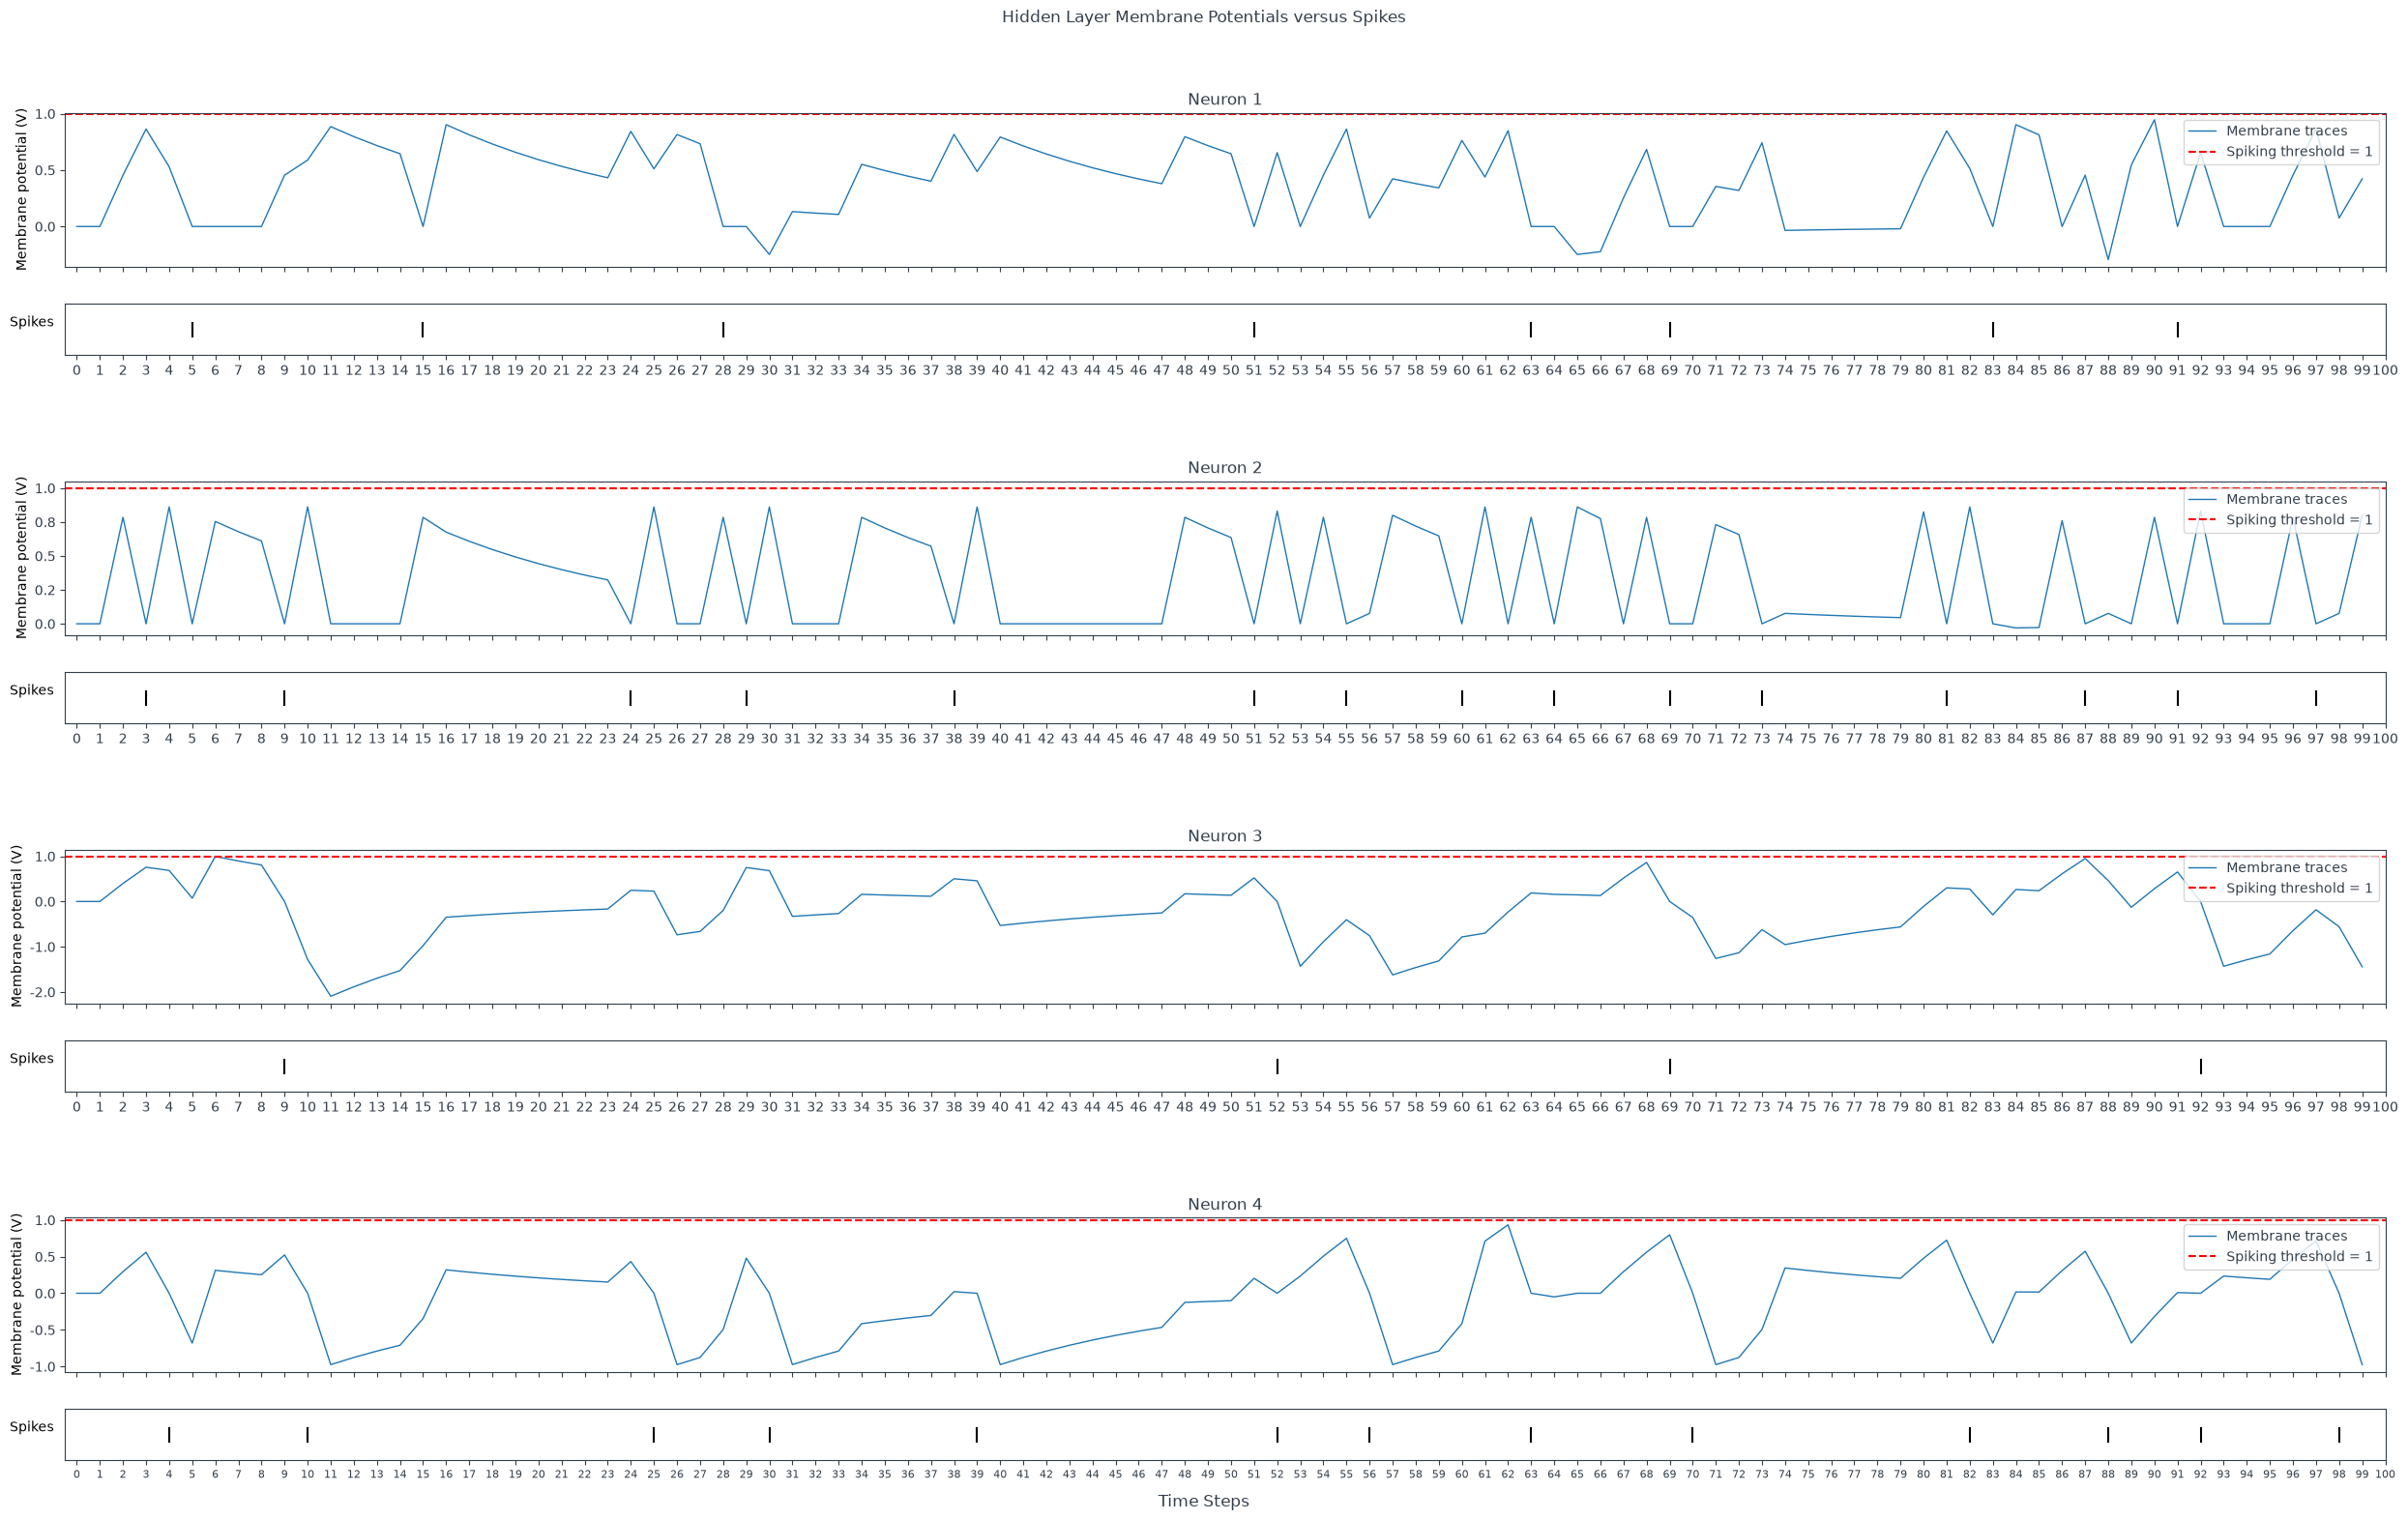

tensor([[1.3769],
        [2.5745],
        [2.7969],
        [0.0845]])
Input weights are all positive
The minimum distance between any two spikes = [ 5.  5.  5. nan], which should be higher than the set refractory period of 4


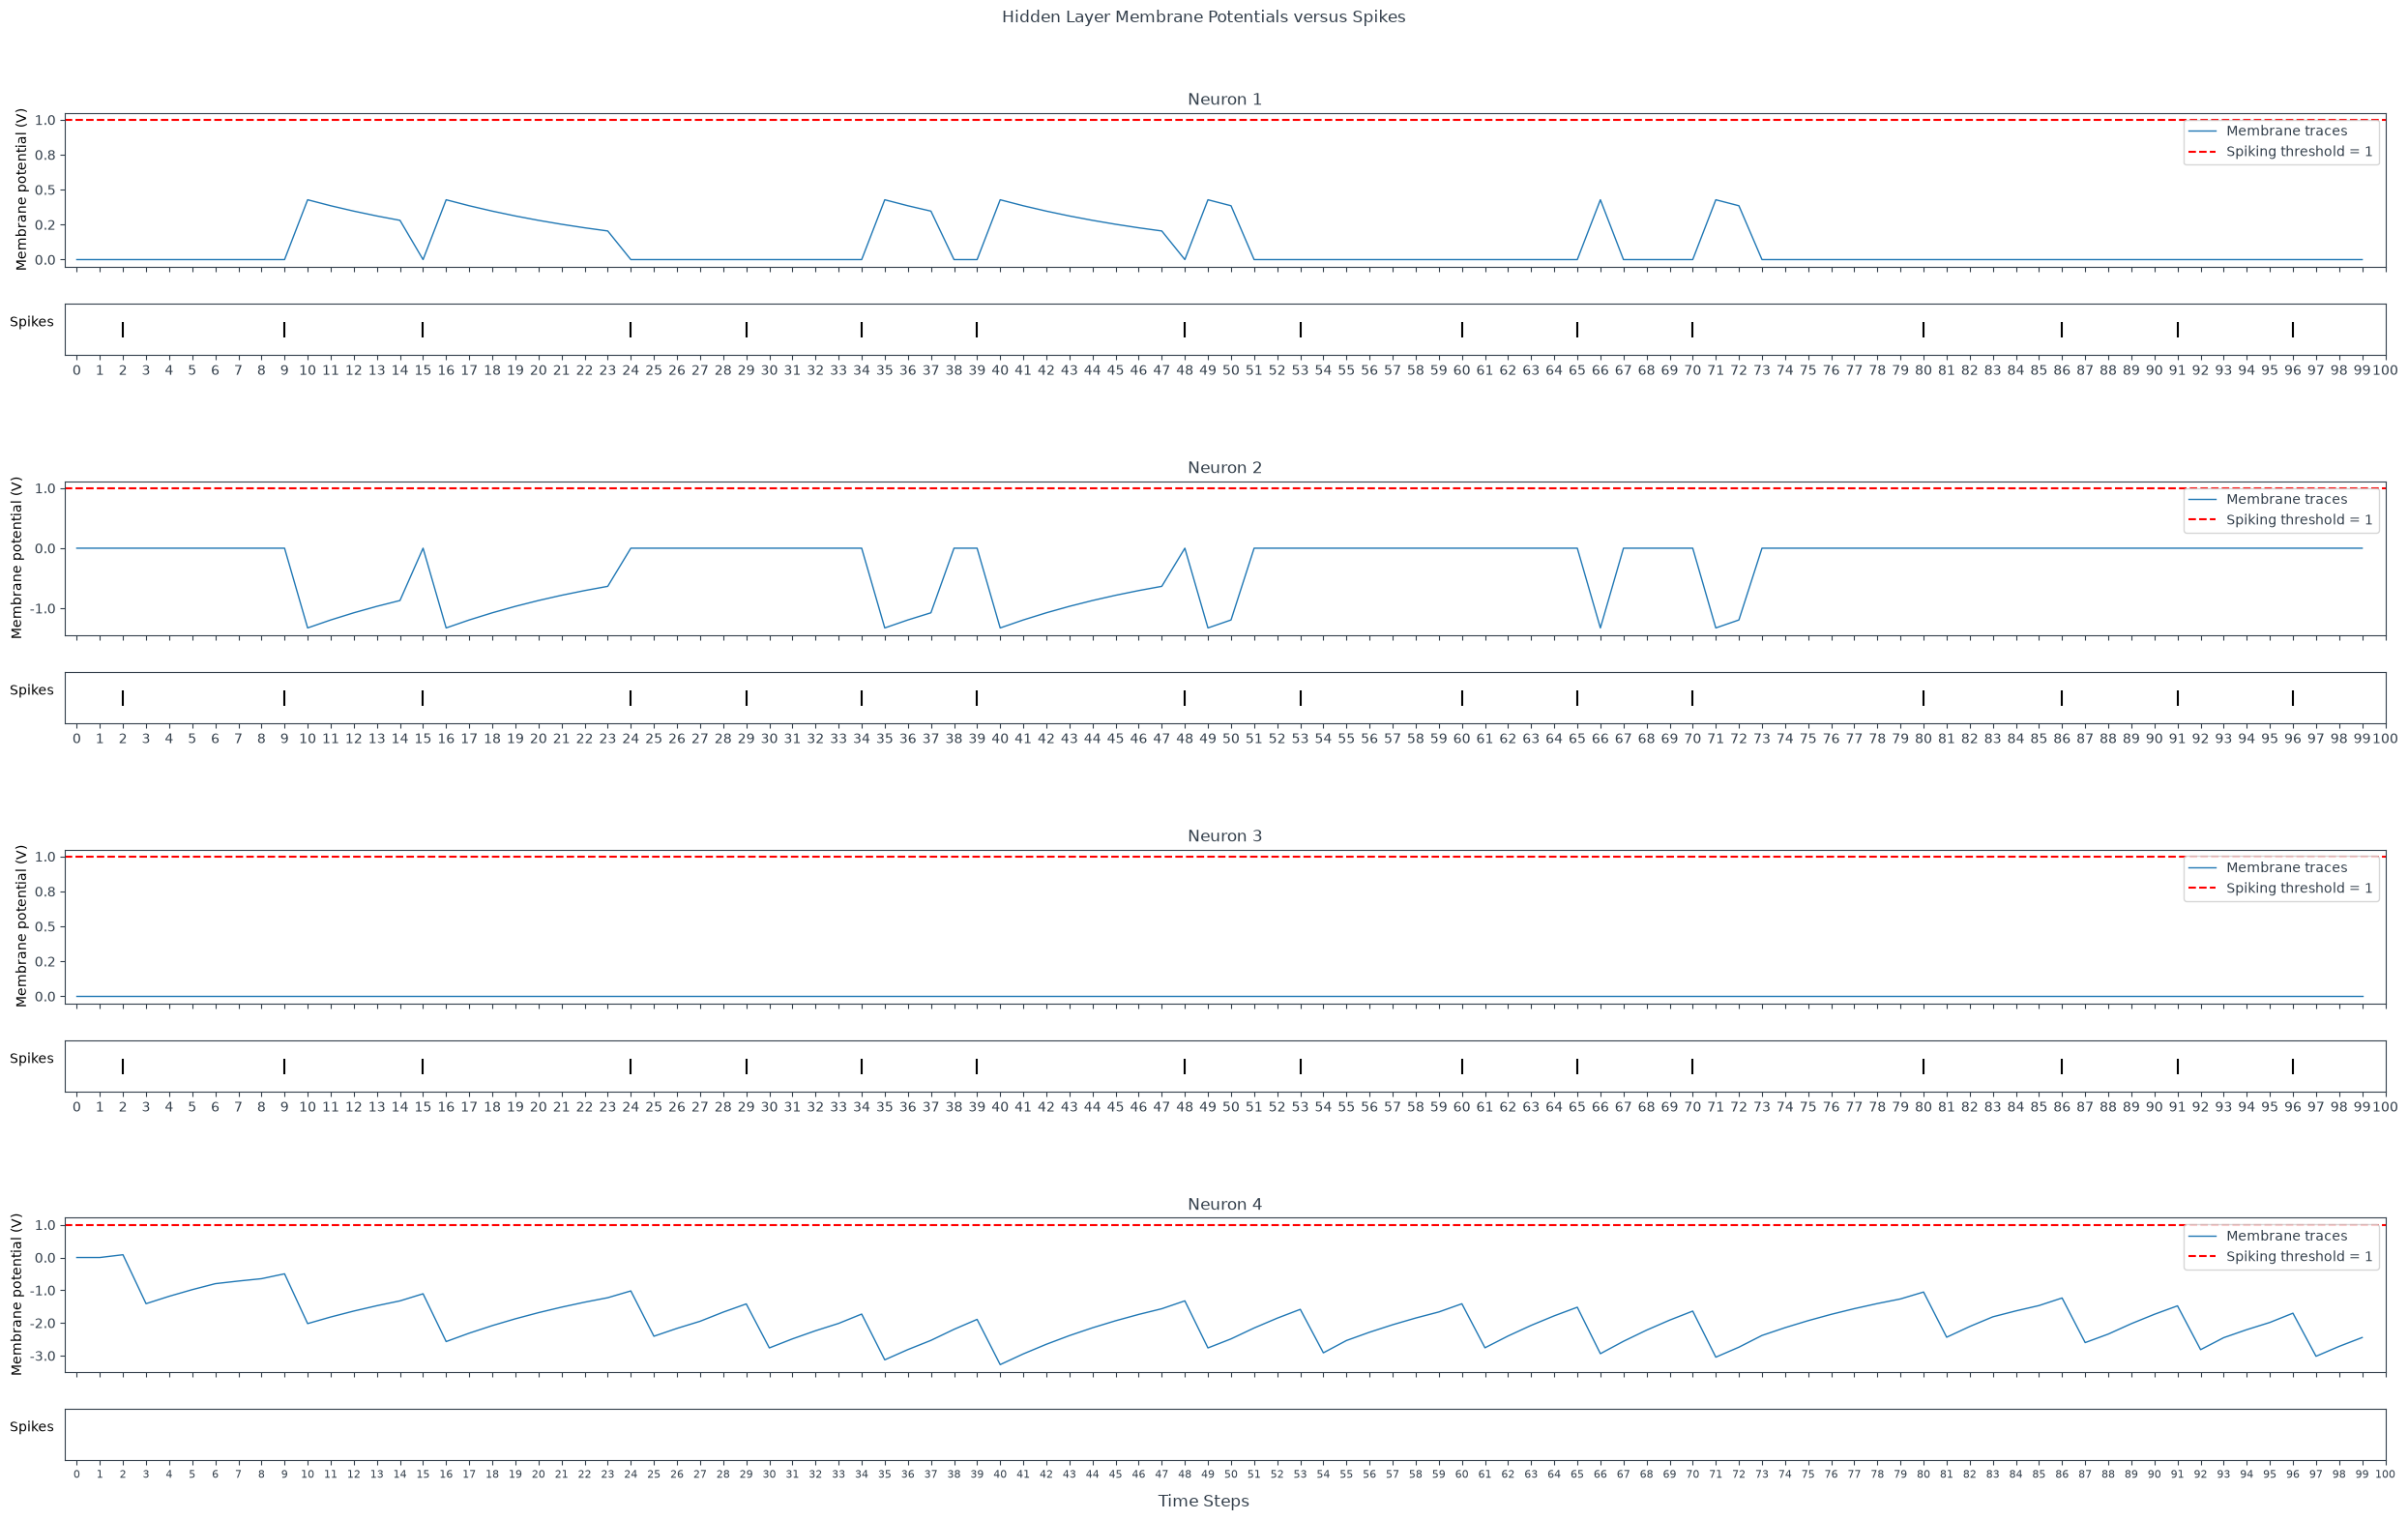

tensor([[0.5994],
        [1.3621],
        [0.0373],
        [1.7707]])
Input weights are all positive
The minimum distance between any two spikes = [ 7.  6. nan  6.], which should be higher than the set refractory period of 5


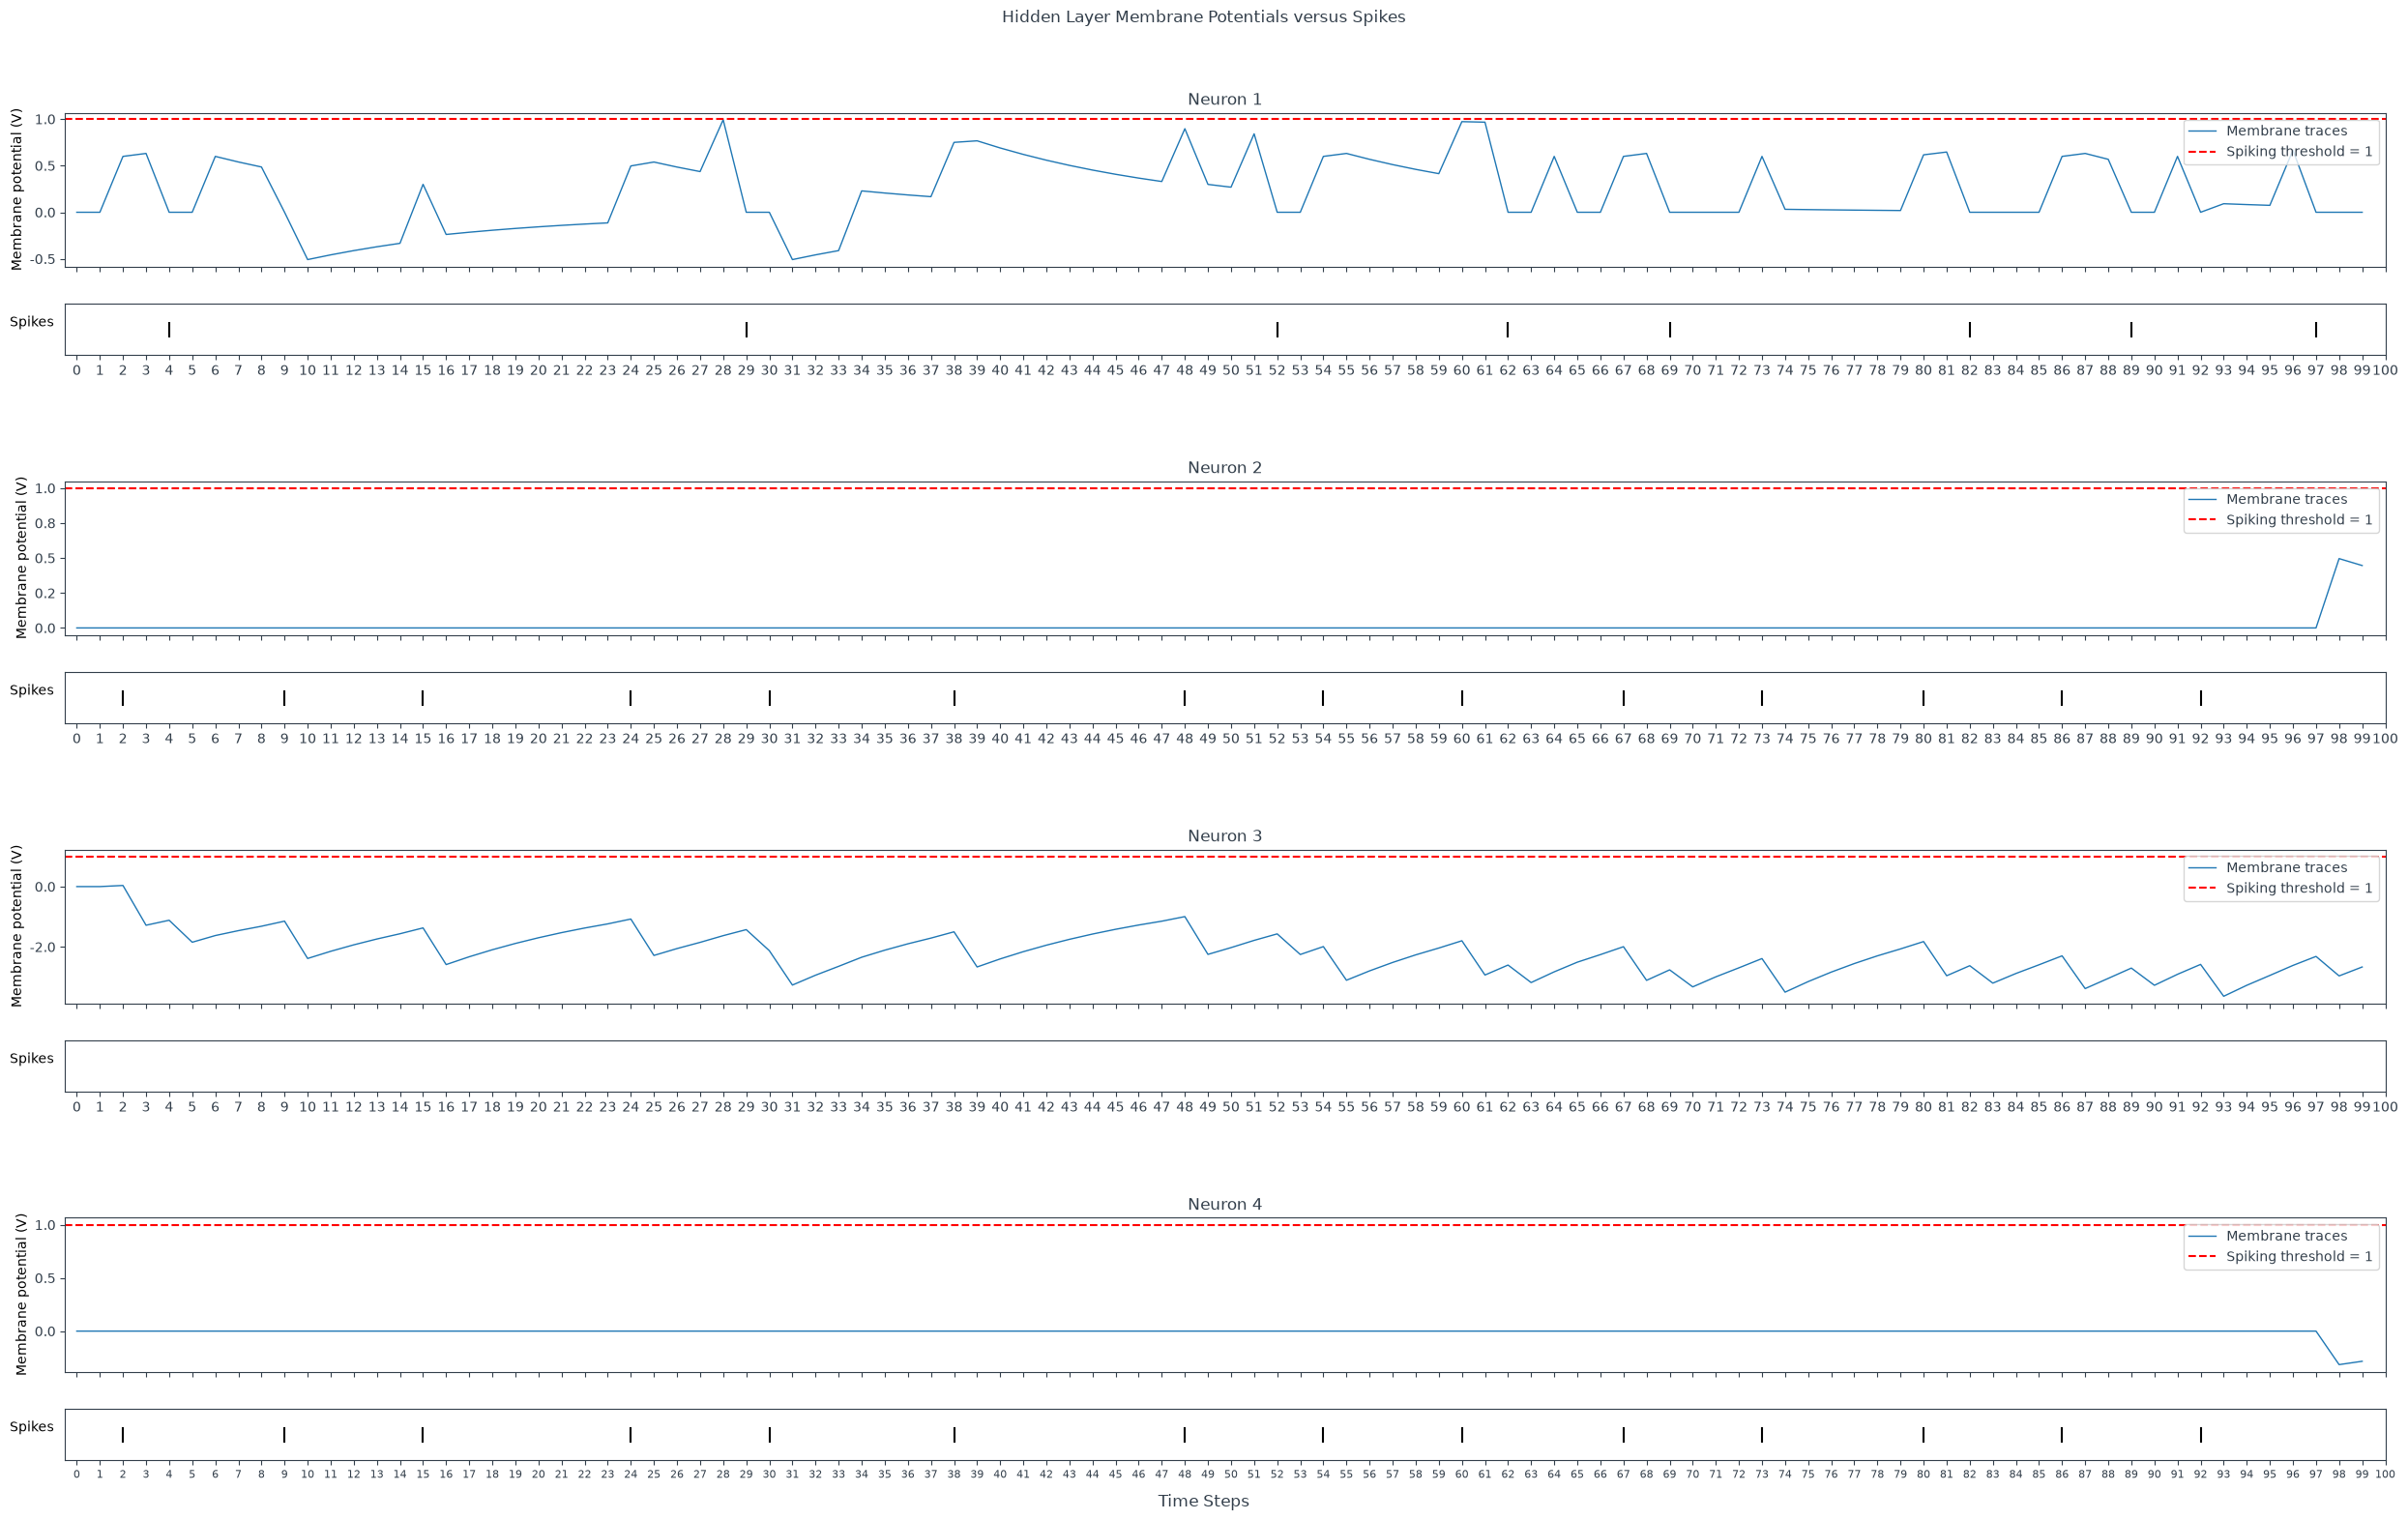

In [249]:
from snntorch.surrogate import fast_sigmoid

from thesis_code.network_components.layers import OutputLayer

refractory_periods = [0, 1, 2, 3, 4, 5]

p_spike_in = 0.5
n_in = 1
n_hidden = 4

num_steps = 100
raw_vector = torch.ones(num_steps, n_in)*p_spike_in
rate_coded_vector = torch.bernoulli(raw_vector)

plot_spikes(rate_coded_vector, "Input Spikes")

for rp in refractory_periods:
    net = SRNN(
        rec_layers=[StandardRecurrentLayer(
            forward_matrix=torch.ones(n_in, n_hidden, device=device),
            recurrent_matrix=torch.ones(n_hidden, n_hidden, device=device),
            beta=0.9,
            spike_grad=fast_sigmoid(slope=25),
            refractory_period=rp,
        )],
        out_layer=OutputLayer(
            n_in=n_hidden,
            n_out=10,
            beta=0.9
        )
    ).to(device)

    data = rate_coded_vector.unsqueeze(1)
    spk_outs, mem_outs, hidden_spks, hidden_mems = net.forward_sequence(data)
    hidden_spks = hidden_spks[0].squeeze().detach().numpy()
    hidden_mems = hidden_mems[0].squeeze().detach().numpy()

    min_spk_dist = isi_per_neuron(hidden_spks, time_axis=0)
    print(f"The minimum distance between any two spikes = {min_spk_dist}, which should be higher than the set refractory period of {rp}")

    # plot_spikes(hidden_spks, "Hidden Layer Spikes")
    plot_membrane_potentials(hidden_mems, hidden_spks, 1, "Hidden Layer Membrane Potentials versus Spikes")
    plt.show()
    # anim = plot_spike_counts(hidden_spks, "Hidden Layer Spike Counts")